<a href="https://colab.research.google.com/github/vollemax-lgtm/F1-explainer/blob/main/04a_chronos2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04a · Chronos-2 Forecasts (Amazon foundation model)

**Owner:** Max · **Reads:** notebook 01 outputs · **Feeds:** Elena (calibration, ensemble), Prateek (hybrid residual model)

Chronos-2 is a pretrained time series model. We give it each product's sales history and it forecasts the next 28 days, **with no training on our data**.

**Two runs**
| Run | Model name in files | What the model sees |
|---|---|---|
| Zero-shot | `chronos2_zs` | Sales history only |
| With covariates | `chronos2_cov` | Sales history + price, discount ratio, SNAP days, events, Christmas (all known in advance) |

**Seven windows per run:** 4 backtests (`bt_4` … `bt_1`), `val_1`, `val_2`, `test`.
Backtests and validation forecasts are what the calibration, ensemble and hybrid steps learn from.

**Output:** `data/forecasts/<model>_<window>.parquet` with columns
`unique_id, ds, model, window, forecast` (the median) + `mean` + `q0.1 … q0.9`.

**Runtime:** set **Runtime → Change runtime type → T4 GPU** before running.
Start with `SAMPLE = True` (100 products, a few minutes). Then set `SAMPLE = False` for all of California.
If Colab disconnects, just run everything again: finished windows are skipped.

## 0 · Settings

In [ ]:
SAMPLE      = True      # True = 100-product smoke test; False = all ~12,200 California series
RUNS        = ["zs", "cov"]   # zero-shot, with covariates
N_BACKTEST  = 4         # extra 28-day windows before val_1 (training data for the hybrid model)
BATCH_SIZE  = 128       # series per GPU batch; lowered automatically if the GPU runs out of memory
OVERWRITE   = False     # True = redo windows that already have a forecast file

DRIVE_DIR   = "/content/drive/MyDrive/AML_Term_Project"
DATA_DIR    = f"{DRIVE_DIR}/data"
OUT_DIR     = f"{DATA_DIR}/forecasts_sample" if SAMPLE else f"{DATA_DIR}/forecasts"

MODEL_ID    = "amazon/chronos-2"
QUANTILES   = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
COVARIATES  = ["sell_price", "price_ratio", "snap", "is_event", "is_christmas"]   # known in advance for future dates

## 1 · Install and connect

In [ ]:
!pip install -q "chronos-forecasting==2.3.2"

In [ ]:
import os, json, time
import numpy as np
import pandas as pd
import torch

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab: using the paths in Settings as-is.")

os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| torch", torch.__version__)
if DEVICE == "cpu":
    print("WARNING: no GPU found. Set Runtime -> Change runtime type -> T4 GPU, or expect this to be slow.")

Mounted at /content/drive
Device: cuda | torch 2.11.0+cu130


## 2 · Load data and windows

In [ ]:
df = pd.read_parquet(f"{DATA_DIR}/{'ca_sample100' if SAMPLE else 'ca_sales'}.parquet")
df["unique_id"] = df["unique_id"].astype(str)
df["ds"] = pd.to_datetime(df["ds"])
df = df.sort_values(["unique_id", "ds"]).reset_index(drop=True)

with open(f"{DATA_DIR}/windows.json") as f:
    wjson = json.load(f)
H = wjson["horizon"]

# Shared window list: 4 backtests right before val_1, then val_1, val_2, test.
# Every notebook builds this list the same way.
val1_start = pd.Timestamp(wjson["val_1"]["start"])
windows = {}
for k in range(N_BACKTEST, 0, -1):
    start = val1_start - pd.Timedelta(days=H * k)
    windows[f"bt_{k}"] = (start, start + pd.Timedelta(days=H - 1))
for name in ["val_1", "val_2", "test"]:
    windows[name] = (pd.Timestamp(wjson[name]["start"]), pd.Timestamp(wjson[name]["end"]))

print(f"{df['unique_id'].nunique():,} series, {len(df):,} rows")
pd.DataFrame({w: {"start": s.date(), "end": e.date()} for w, (s, e) in windows.items()}).T

100 series, 146,311 rows


,start,end
bt_4,2015-11-09,2015-12-06
bt_3,2015-12-07,2016-01-03
bt_2,2016-01-04,2016-01-31
bt_1,2016-02-01,2016-02-28
val_1,2016-02-29,2016-03-27
val_2,2016-03-28,2016-04-24
test,2016-04-25,2016-05-22


## 3 · Load Chronos-2

In [ ]:
from chronos import Chronos2Pipeline
pipeline = Chronos2Pipeline.from_pretrained(MODEL_ID, device_map=DEVICE)
print("Loaded", MODEL_ID)

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loaded amazon/chronos-2


## 4 · Forecast one window
For a window starting on day *S*:
- **History** = every row before *S* (the model never sees the window's actual sales)
- **Future covariates** = price and calendar values for the 28 window days (known in advance in real life)
- Products launched on or after *S* have no history, so they're skipped for that window

In [ ]:
def forecast_window(run, wname, start, end, batch_size=BATCH_SIZE):
    hist = df[df["ds"] < start]
    ids = hist["unique_id"].unique()
    future_mask = (df["ds"] >= start) & (df["ds"] <= end) & df["unique_id"].isin(ids)

    if run == "zs":
        context = hist[["unique_id", "ds", "y"]]
        future = None
    else:
        context = hist[["unique_id", "ds", "y"] + COVARIATES]
        future = df.loc[future_mask, ["unique_id", "ds"] + COVARIATES]
        # A product must have all 28 future rows to be forecast with covariates
        full = future.groupby("unique_id").size()
        keep = full[full == H].index
        context, future = context[context["unique_id"].isin(keep)], future[future["unique_id"].isin(keep)]

    while True:
        try:
            out = pipeline.predict_df(
                context, future_df=future,
                id_column="unique_id", timestamp_column="ds", target="y",
                prediction_length=H, quantile_levels=QUANTILES, batch_size=batch_size,
            )
            break
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            batch_size //= 2
            print(f"  GPU out of memory -> retrying with batch_size={batch_size}")
            if batch_size < 4:
                raise

    res = pd.DataFrame({
        "unique_id": out["unique_id"].astype(str),
        "ds": pd.to_datetime(out["ds"]),
        "model": f"chronos2_{run}",
        "window": wname,
        "forecast": out["0.5"].clip(lower=0).astype("float32"),   # median, no negative sales
        "mean": out["predictions"].clip(lower=0).astype("float32"),
    })
    for q in QUANTILES:
        res[f"q{q}"] = out[str(q)].clip(lower=0).astype("float32")
    return res, batch_size

## 5 · Run everything (skips windows already saved)

In [ ]:
log_rows = []
for run in RUNS:
    for wname, (start, end) in windows.items():
        path = f"{OUT_DIR}/chronos2_{run}_{wname}.parquet"
        if os.path.exists(path) and not OVERWRITE:
            print(f"skip  chronos2_{run:3s} {wname:6s} (already saved)")
            continue
        t0 = time.time()
        res, used_bs = forecast_window(run, wname, start, end)
        res.to_parquet(path, index=False)
        secs = time.time() - t0
        n = res["unique_id"].nunique()
        print(f"done  chronos2_{run:3s} {wname:6s} {n:6,} series  {secs:6.1f}s")
        log_rows.append({"model": f"chronos2_{run}", "window": wname, "series": n, "seconds": round(secs, 1),
                         "batch_size": used_bs, "device": DEVICE, "sample": SAMPLE,
                         "run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")})

if log_rows:
    log_path = f"{OUT_DIR}/run_log.csv"
    new = pd.DataFrame(log_rows)
    new.to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
    display(new)

done  chronos2_zs  bt_4      100 series     2.9s
done  chronos2_zs  bt_3      100 series     1.1s
done  chronos2_zs  bt_2      100 series     0.9s
done  chronos2_zs  bt_1      100 series     1.0s
done  chronos2_zs  val_1     100 series     1.0s
done  chronos2_zs  val_2     100 series     1.0s
done  chronos2_zs  test      100 series     1.4s
done  chronos2_cov bt_4      100 series     5.3s
done  chronos2_cov bt_3      100 series     5.3s
done  chronos2_cov bt_2      100 series     5.4s
done  chronos2_cov bt_1      100 series     5.8s
done  chronos2_cov val_1     100 series     5.9s
done  chronos2_cov val_2     100 series     5.7s
done  chronos2_cov test      100 series     5.9s


,model,window,series,seconds,batch_size,device,sample,run_at
0,chronos2_zs,bt_4,100,2.9,128,cuda,True,2026-10-28 20:02
1,chronos2_zs,bt_3,100,1.1,128,cuda,True,2026-10-28 20:02
2,chronos2_zs,bt_2,100,0.9,128,cuda,True,2026-10-28 20:02
3,chronos2_zs,bt_1,100,1.0,128,cuda,True,2026-10-28 20:02
4,chronos2_zs,val_1,100,1.0,128,cuda,True,2026-10-28 20:02
5,chronos2_zs,val_2,100,1.0,128,cuda,True,2026-10-28 20:02
6,chronos2_zs,test,100,1.4,128,cuda,True,2026-10-28 20:02
7,chronos2_cov,bt_4,100,5.3,128,cuda,True,2026-10-28 20:02
8,chronos2_cov,bt_3,100,5.3,128,cuda,True,2026-10-28 20:02
9,chronos2_cov,bt_2,100,5.4,128,cuda,True,2026-10-28 20:02


## 6 · Quick check against a simple baseline
Not the official evaluation (that's notebook 05). This just confirms the forecasts are sensible:
Chronos-2 should beat "same weekday last week" on most windows.

In [ ]:
actual = df[["unique_id", "ds", "y"]]
lag7 = df[["unique_id", "ds", "y"]].copy()
lag7["ds"] = lag7["ds"] + pd.Timedelta(days=7)
lag7 = lag7.rename(columns={"y": "naive"})

rows = []
for run in RUNS:
    for wname in windows:
        f = pd.read_parquet(f"{OUT_DIR}/chronos2_{run}_{wname}.parquet")
        m = f.merge(actual, on=["unique_id", "ds"]).merge(lag7, on=["unique_id", "ds"], how="left")
        m["naive"] = m["naive"].fillna(0)
        rows.append({"model": f"chronos2_{run}", "window": wname,
                     "MAE chronos": (m["forecast"] - m["y"]).abs().mean(),
                     "MAE naive": (m["naive"] - m["y"]).abs().mean()})
check = pd.DataFrame(rows)
check["improvement vs naive"] = (1 - check["MAE chronos"] / check["MAE naive"]).map("{:.0%}".format)
check.round(3)

,model,window,MAE chronos,MAE naive,improvement vs naive
0,chronos2_zs,bt_4,0.896,1.211,26%
1,chronos2_zs,bt_3,0.860,1.163,26%
2,chronos2_zs,bt_2,0.969,1.340,28%
3,chronos2_zs,bt_1,0.933,1.269,26%
4,chronos2_zs,val_1,0.958,1.226,22%
5,chronos2_zs,val_2,0.922,1.259,27%
6,chronos2_zs,test,1.012,1.297,22%
7,chronos2_cov,bt_4,0.884,1.211,27%
8,chronos2_cov,bt_3,0.861,1.163,26%
9,chronos2_cov,bt_2,0.952,1.340,29%


## 7 · Look at a few products
Actual sales (black) vs. Chronos-2's median and 10th–90th percentile range on the **test** window.

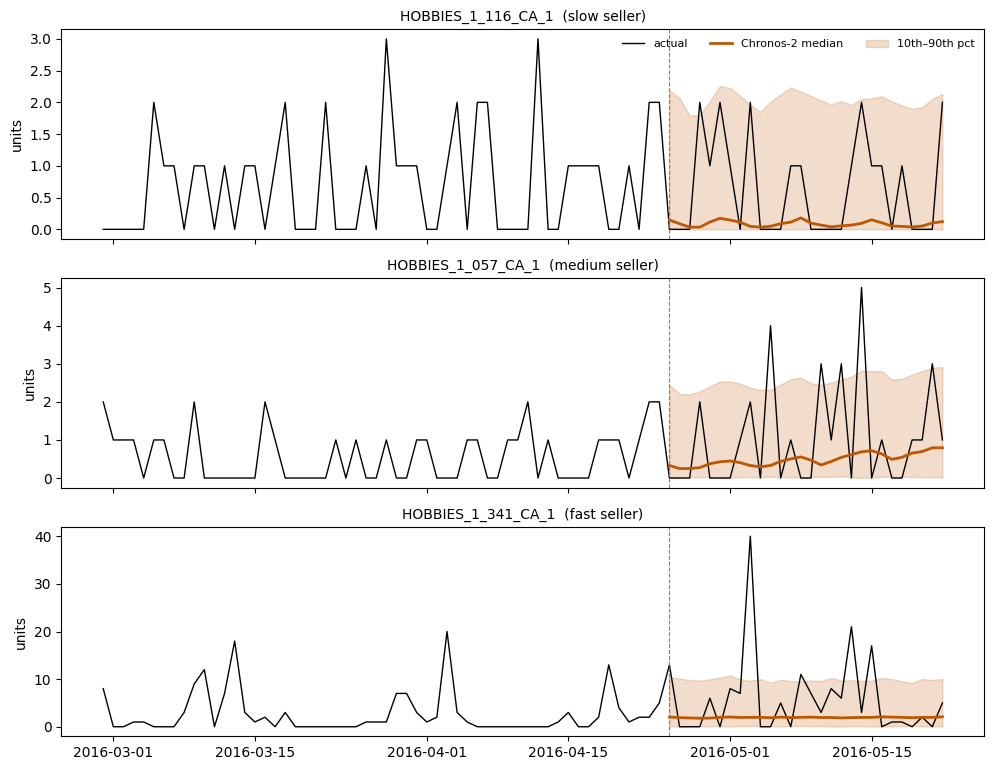

In [ ]:
import matplotlib.pyplot as plt
run = "cov" if "cov" in RUNS else RUNS[0]
f = pd.read_parquet(f"{OUT_DIR}/chronos2_{run}_test.parquet")
start, end = windows["test"]
# one fast, one medium, one slow seller from the sample
static = pd.read_parquet(f"{DATA_DIR}/ca_static.parquet")
static["unique_id"] = static["unique_id"].astype(str)
pick = (static[static["unique_id"].isin(f["unique_id"])]
        .groupby("sales_speed", observed=True)["unique_id"].first())

fig, axes = plt.subplots(len(pick), 1, figsize=(10, 2.6 * len(pick)), sharex=True)
for ax, (speed, uid) in zip(np.atleast_1d(axes), pick.items()):
    hist = df[(df["unique_id"] == uid) & (df["ds"] >= start - pd.Timedelta(days=56)) & (df["ds"] <= end)]
    fc = f[f["unique_id"] == uid]
    ax.plot(hist["ds"], hist["y"], color="black", lw=1, label="actual")
    ax.plot(fc["ds"], fc["forecast"], color="#BF5700", lw=2, label="Chronos-2 median")
    ax.fill_between(fc["ds"], fc["q0.1"], fc["q0.9"], color="#BF5700", alpha=0.2, label="10th–90th pct")
    ax.axvline(start, color="grey", ls="--", lw=0.8)
    ax.set_title(f"{uid}  ({speed} seller)", fontsize=10); ax.set_ylabel("units")
np.atleast_1d(axes)[0].legend(frameon=False, ncol=3, fontsize=8)
plt.tight_layout()
os.makedirs(f"{DATA_DIR}/figures", exist_ok=True)
if not SAMPLE:
    plt.savefig(f"{DATA_DIR}/figures/10_chronos2_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## What to report back
After running, download this notebook (**File → Download → .ipynb**) with outputs and save it over the copy in *Project Code*, or commit it to GitHub.
Key things to look at:
1. Section 5: seconds per window (tells us how long the full run takes)
2. Section 6: does Chronos-2 beat the naive baseline? Does `cov` beat `zs`?
3. Section 7: do the forecast ranges look sensible for fast vs. slow sellers?